# SafeSight: Construction PPE Recognition with Neural Networks
____________________________________________________________________________________________________

MLAI 504, Neural Networks and Deep Learning, course project.

In this notebook we classify image regions from construction sites into **4 PPE classes**: Hardhat, NO-Hardhat, Safety Vest and NO-Safety Vest. We start from a simple MLP, build CNNs **from scratch**, measure which design choices matter, and finally use **transfer learning** with a MobileNetV2 pre-trained on ImageNet.

**Research question:** can a pre-trained MobileNetV2 recognize PPE regions, and especially *missing* PPE, more reliably than a dense network or a CNN trained from scratch?

We will do the following steps in order:

1. Dataset selection
2. Data preprocessing: annotation audit, outlier rule, cropping, exploration, leakage check, normalization
3. Step-by-step model creation: MLP, then CNNs
4. Hyperparameter tuning: one change at a time, grid search over learning rate x batch size, then combination of the best settings
5. Transfer learning: frozen, partially and fully fine-tuned MobileNetV2, with 10% and 100% of the data
6. Integration of the course topics
7. Evaluation on the unseen test data
8. Conclusion

Appendix: demo, load any saved checkpoint and test it.

**Scope:** the model classifies regions that are already annotated with a bounding box. It does not detect PPE in full images and does not link the equipment to a specific worker.

**Note:** with `RETRAIN = False`, an experiment is only trained if its checkpoint is not saved yet in `Checkpoints/` (useful if the training stops in the middle); the others are loaded. Experiments 01 to 06 were trained first on a CPU, the experiments added later (4.1, 4.2, 4.4, 5.3, 5.4) on a Google Colab T4 GPU, so training times can only be compared on the same hardware (column `device`).

All the reusable code (data pipeline, models, training loop, metrics and plots) is in `utils.py`, next to this notebook.

## 0. Google Colab setup

Only runs on Google Colab (skipped automatically when running locally).

This cell:
1. mounts Google Drive and clones the repository into `My Drive/Neural-Networks-and-Deep-Learning` (first run only), so checkpoints and results are saved on Drive and are not lost when the session ends
2. moves into the `Notebooks/` folder so that `import utils` and the relative paths work
3. installs `roboflow`, the only package that is not already installed on Colab (locally: `pip install -r requirements.txt`)

On Colab: **Runtime → Change runtime type → T4 GPU**. To download the dataset, add a Colab secret (🔑 in the left sidebar) named `ROBOFLOW_API_KEY` with your Roboflow **private** API key and turn on notebook access.

In [5]:
import os
import subprocess
import sys

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

    PROJECT_DIR = '/content/drive/MyDrive/Neural-Networks-and-Deep-Learning'  # folder of the project on Google Drive
    if not os.path.exists(PROJECT_DIR):  # first run only
        subprocess.run(['git', 'clone', '-b', 'ai-style-experiments',
                        'https://github.com/MohammedZaiter/Neural-Networks-and-Deep-Learning.git', PROJECT_DIR], check=True)
    os.chdir(PROJECT_DIR + '/Notebooks')
    sys.path.insert(0, os.getcwd())  # so that "import utils" finds utils.py
    # keras==3.15.1: the version that saved the checkpoints; older versions cannot load them
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'roboflow>=1.1,<3', 'keras==3.15.1'], check=True)
    print('Working directory:', os.getcwd())

## Settings

One seed (504) for Python, NumPy and TensorFlow, the output folders, and the configuration below (saved in `results/configuration.json`).

In [6]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

import utils
from utils import CONFIG, TARGET, SEED

RETRAIN = False  # False -> load every experiment that has a checkpoint in Checkpoints/, train only the missing ones
utils.setup(RETRAIN)
print(CONFIG)

TensorFlow: 2.19.1 | device: CPU | retrain: False
{'workspace': 'roboflow-universe-projects', 'project': 'construction-site-safety', 'version': 27, 'image_size': 160, 'crop_padding': 0.1, 'min_box_pixels': 12, 'batch_size': 32, 'scratch_epochs': 15, 'transfer_epochs': 15, 'fine_tune_epochs': 8, 'ablation_epochs': 15, 'long_epochs': 30, 'best_cnn_epochs': 30, 'tl_compare_epochs': 10, 'small_fraction': 0.1}


## 1. Dataset selection

**Source:** [Construction Site Safety, version 27](https://universe.roboflow.com/roboflow-universe-projects/construction-site-safety/dataset/27) on Roboflow Universe, CC BY 4.0 licence.

**Why this dataset:** missing hard hats and safety vests are among the most visible and preventable risks on construction sites. The dataset is public and labelled, and it has explicit *missing*-PPE classes (`NO-Hardhat`, `NO-Safety Vest`), so the task has a direct safety meaning.

| property | value |
|---|---|
| size | 2,799 images: 2,603 train / 114 validation / 82 test (Roboflow lists 2,801) |
| origin | augmented export of a 717-image source project, so the images are not all independent scenes |
| features | RGB photos with YOLO bounding boxes `(class_id, cx, cy, width, height)`, normalized to [0, 1] |
| source classes | 10: Hardhat, Mask, NO-Hardhat, NO-Mask, NO-Safety Vest, Person, Safety Cone, Safety Vest, machinery, vehicle |
| **target variable** | 4 classes: **Hardhat, NO-Hardhat, Safety Vest, NO-Safety Vest** |
| unit of analysis | one annotated box (a crop), not a whole image |

Only the 4 PPE classes are kept; the boxes of the 6 other classes are ignored. The dataset is loaded from `data/`, or downloaded with a Roboflow API key.

In [7]:
# Dataset location, in priority order: LOCAL_DATASET_DIR, data/Construction-Site-Safety-27/,
# or a download from Roboflow with ROBOFLOW_API_KEY (environment variable or Colab secret)
DATA, names = utils.find_dataset()
print('DATA:', DATA, 'classes:', names)

DATA: C:\Users\MohammedZaiter\source\repos\GitHub\Neural-Networks-and-Deep-Learning\data\Construction-Site-Safety-27 classes: {0: 'Hardhat', 1: 'Mask', 2: 'NO-Hardhat', 3: 'NO-Mask', 4: 'NO-Safety Vest', 5: 'Person', 6: 'Safety Cone', 7: 'Safety Vest', 8: 'machinery', 9: 'vehicle'}


## 2. Data preprocessing

### 2.1 Annotation audit, outlier rule and cropping

Every YOLO box becomes one example (a crop). Before cropping, each image and label row is checked:

| problem | what we do |
|---|---|
| **missing values:** unreadable image, missing label file, malformed or non-numeric row | logged in an audit table and skipped, never imputed |
| invalid coordinates (not finite, zero or negative size, centre outside the image) | logged and skipped |
| **outliers:** boxes smaller than 12 px after clipping | removed by a fixed rule chosen before training |

Each box is padded by 10% for context and clipped to the image borders. Every crop keeps the name of its parent image, so it can be traced back.

In [8]:
# Audit every image and label row, apply the outlier rule, and list one crop per valid box
DF, AUD = utils.audit_and_crop(DATA, names)
print('Region counts by split and class:')
display(pd.crosstab(DF.split, DF.label).rename(columns=dict(enumerate(TARGET))))
print('Audit totals:', AUD.reason.value_counts().to_dict())

Source label mapping: {'Hardhat': 'Hardhat', 'NO-Hardhat': 'NO-Hardhat', 'NO-Safety Vest': 'NO-Safety Vest', 'Safety Vest': 'Safety Vest'}
Region counts by split and class:


label,Hardhat,NO-Hardhat,Safety Vest,NO-Safety Vest
split,,,,
test,102,29,61,77
train,2803,2010,2797,3805
valid,73,52,38,92


Audit totals: {'small clipped box': 1451}


### 2.2 Data exploration

Class balance per split, size of the crops (very small crops carry little information once resized to 160x160), and two training crops per class.

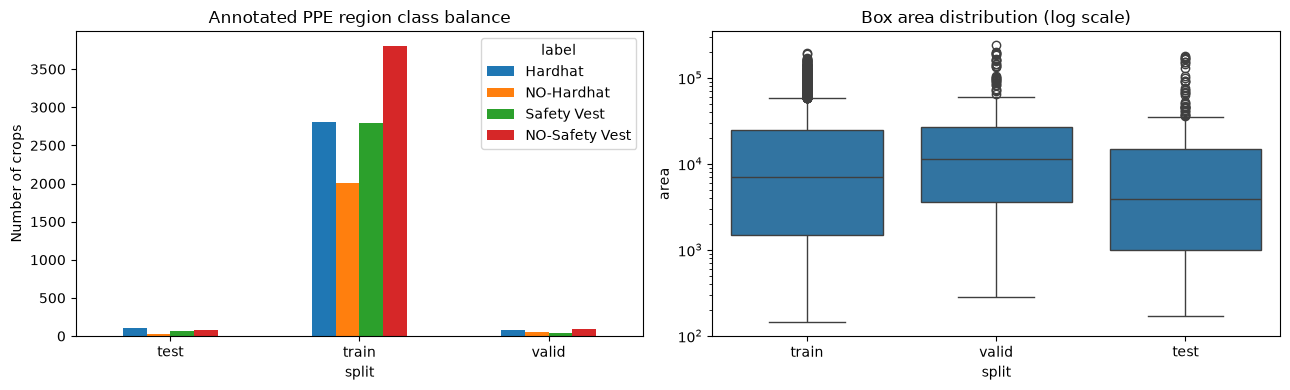

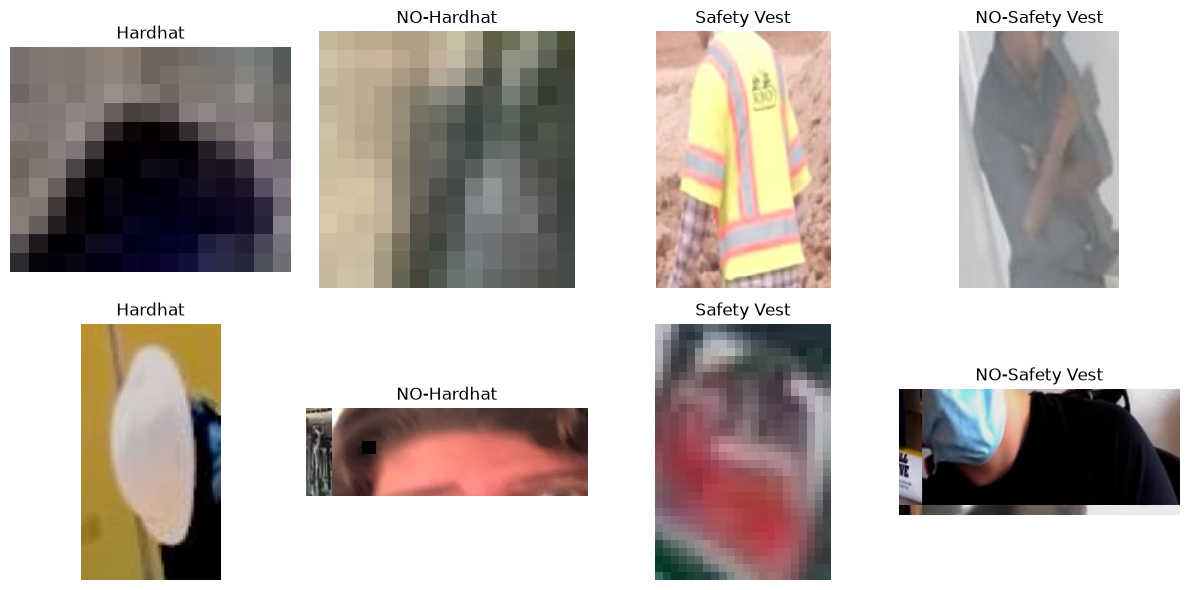

In [9]:
# Class balance per split, crop size distribution (box area in pixels), and two random training crops per class
utils.plot_dataset(DF)

### 2.3 Duplicate and leakage check

Augmented exports can contain identical images under different file names, so we compare the SHA-256 hash of every parent image across splits. The crops are **not** shuffled into new splits after cropping: that would put almost identical regions of the same image into both training and test.

In [10]:
# Exact-duplicate check: SHA-256 of every parent image, compared across splits
utils.duplicate_check(DF)

train/valid exact-image hash overlaps: 0
train/test exact-image hash overlaps: 0
valid/test exact-image hash overlaps: 0
Note: augmented/near-duplicate detection also requires perceptual review beyond SHA256.


### 2.4 Normalization, augmentation and class weights

- **Splits:** the predefined Roboflow partitions are used as they are. Training data fits the weights, validation is used for every modelling decision, and test is used **only at the end**.
- **Normalization:** crops are converted from BGR to RGB, resized to 160x160 and scaled to [0, 1]. MobileNetV2 expects [-1, 1], so its model adds a rescaling layer $x \rightarrow 2x - 1$ (section 5).
- **Augmentation (training only):** random horizontal flip, rotation up to ±7% of a full turn (about ±25°) and contrast change up to ±12%, as model layers that Keras switches off at inference. No grayscale and no aggressive cropping, because colour and shape are the main cues.
- **Class weights:** inverse class frequency, so that errors on the rarer classes cost more in the loss:

$$w_c = \frac{N}{4 \times n_c}$$

where $N$ is the number of training crops and $n_c$ the number of crops of class $c$.

Each crop is cut and resized once and kept in memory as 8-bit pixels (about 0.9 GB, also saved in `data/`). Re-reading every crop from its JPEG in every epoch was the main bottleneck of the first, CPU-only run.

In [11]:
# Cut every crop once and keep it in memory; build the training index and the class weights
utils.prepare_data(DF)
DF = utils.DF   # the crop table used by every experiment
print('Training class weights:', utils.CLASS_WEIGHT)

11,939 crops in memory (0.92 GB)
Training class weights: {0: 1.018105601141634, 1: 1.419776119402985, 2: 1.0202895959957097, 3: 0.75}


## Observations (data)

- **Clean annotations:** no unreadable images, missing label files, malformed rows or invalid coordinates. The only rejections are **1,451 boxes** removed by the small-box rule.
- **11,939 crops in total:** 11,415 train, 255 validation and 269 test. All 4 classes appear in every split.
- **Imbalance:** in training, NO-Safety Vest has 3,805 crops and NO-Hardhat 2,010 (ratio about 1.9). NO-Hardhat gets a class weight of 1.42 and NO-Safety Vest 0.75, so a missed NO-Hardhat crop costs almost twice as much in the loss.
- **Crop sizes:** box areas go from about 150 px² to more than 100,000 px². The median is about 7,000 px² in training but only 4,000 px² in test, so the **test crops are smaller and harder** than the crops used to choose the model. Many crops are under 32x32 px and are blurred when enlarged to 160x160.
- **Leakage:** no exact duplicates across splits. Hashing cannot find near-duplicates (for example an augmented copy of a training scene), so this stays a limitation (section 7.5).
- **Small evaluation sets:** at an accuracy near 0.9, 269 test crops give a 95% confidence interval of about ±3.6 points, and crops of the same image are correlated. Differences of a few points between models should not be over-interpreted.

## 3. Step-by-step model creation

We start from the simplest network and add structure step by step:

| step | model | what changes | why |
|---|---|---|---|
| 1 | MLP | dense layers on flattened pixels | baseline: a network with no notion of spatial layout (Lectures 02-03) |
| 2 | CNN with ReLU | convolutions, pooling, BatchNorm | local filters with shared weights should find helmet edges and vest textures (Lecture 06) |
| 3 | CNN with ELU + stronger regularization | activation, dropout, L2 and learning rate | does another activation with more regularization generalize better? Four settings change at once, so section 4.1 then tests each one separately |

- **Loss:** sparse categorical cross-entropy (softmax output, one integer label per crop), weighted by the class weights (Lecture 04)
- **Training (`utils.run()`):** Adam (or SGD with momentum 0.9), **early stopping** after 4 epochs without improvement of the validation loss (best weights kept), **ReduceLROnPlateau** (learning rate halved after 2 epochs without improvement) and a checkpoint of the best epoch in `Checkpoints/<name>.keras`
- **Validation metrics:** accuracy, **macro-F1** (every class weighs the same), balanced accuracy and **unsafe recall**, the mean recall of NO-Hardhat and NO-Safety Vest. Unsafe recall matters most: a missed violation is the most costly error.

### 3.1 Baseline MLP

| layer | details | output shape |
|---|---|---|
| input | RGB crop | 160 x 160 x 3 |
| resizing | to 64x64, otherwise the first dense layer alone would need 9.8M weights | 64 x 64 x 3 |
| flatten | spatial structure is lost here | 12,288 |
| dense + ReLU | | 128 |
| dropout | 0.35 | 128 |
| dense + softmax | | 4 |

1.57M parameters, Adam with learning rate 1e-3.

In [12]:
mlp = utils.run('01_mlp', utils.make_mlp(), 1e-3, CONFIG['scratch_epochs'], group='step-by-step', change='MLP baseline')

01_mlp: loaded trained model from ../Checkpoints/01_mlp.keras
01_mlp {'model': '01_mlp', 'training_seconds': 459.95, 'accuracy': 0.573, 'macro_f1': 0.568, 'balanced_accuracy': 0.592, 'unsafe_recall': 0.574}


### 3.2 CNN with ReLU

Output size of a conv layer:

$$h_{out}=\frac{h_{in} + 2p - k}{s} + 1$$

With 3x3 kernels and "same" padding the size is kept, and each 2x2 max pool divides it by 2.

| layer | details | output shape |
|---|---|---|
| input | RGB crop, augmentation during training | 160 x 160 x 3 |
| conv1 + BatchNorm + ReLU | 24 filters, 3x3, same padding | 160 x 160 x 24 |
| max pool | 2x2 | 80 x 80 x 24 |
| conv2 + BatchNorm + ReLU | 48 filters, 3x3, same padding | 80 x 80 x 48 |
| max pool | 2x2 | 40 x 40 x 48 |
| conv3 + BatchNorm + ReLU | 96 filters, 3x3, same padding | 40 x 40 x 96 |
| max pool | 2x2 | 20 x 20 x 96 |
| global average pooling | one value per filter | 96 |
| dropout | 0.3 | 96 |
| dense + softmax | | 4 |

L2 regularization of 1e-4 on the conv weights, Adam with learning rate 1e-3. Only **53,716 parameters**, 29x fewer than the MLP: convolutions share their weights over the whole image, and global average pooling replaces a big fully connected layer.

This CNN is also the **baseline of section 4.1**: `utils.make_cnn()` has an argument for every setting tested there, and its defaults build exactly this model. The cell also prints the layer table computed from the model.

In [13]:
cnn = utils.run('02_cnn_relu', utils.make_cnn(), 1e-3, CONFIG['scratch_epochs'], group='step-by-step', change='CNN (ReLU)')

# Layer-by-layer view of the baseline CNN
LAYERS = utils.layer_table(cnn)
LAYERS.to_csv(utils.RESULTS / 'cnn_baseline_layers.csv', index=False)
display(LAYERS)
print(f"Total parameters: {cnn.count_params():,} | receptive field: {utils.receptive_field(cnn)} px "
      f"of a {CONFIG['image_size']} x {CONFIG['image_size']} input")

02_cnn_relu: loaded trained model from ../Checkpoints/02_cnn_relu.keras
02_cnn_relu {'model': '02_cnn_relu', 'training_seconds': 3314.14, 'accuracy': 0.702, 'macro_f1': 0.696, 'balanced_accuracy': 0.71, 'unsafe_recall': 0.778}


,layer,type,output_shape,parameters
0,conv2d,Conv2D,160 x 160 x 24,672
1,batch_normalization,BatchNormalization,160 x 160 x 24,96
2,activation,Activation,160 x 160 x 24,0
3,max_pooling2d,MaxPooling2D,80 x 80 x 24,0
4,conv2d_1,Conv2D,80 x 80 x 48,10416
5,batch_normalization_1,BatchNormalization,80 x 80 x 48,192
6,activation_1,Activation,80 x 80 x 48,0
7,max_pooling2d_1,MaxPooling2D,40 x 40 x 48,0
8,conv2d_2,Conv2D,40 x 40 x 96,41568
9,batch_normalization_2,BatchNormalization,40 x 40 x 96,384


Total parameters: 53,716 | receptive field: 22 px of a 160 x 160 input


### 3.3 CNN with ELU and stronger regularization

ELU gives small negative outputs instead of zero, which avoids "dead" ReLU units and keeps the mean activation closer to zero. At the same time we use more regularization (dropout 0.3 → 0.45, L2 1e-4 → 5e-4) and half the learning rate (5e-4), to test whether a more constrained model generalizes better.

In [14]:
# Same architecture as step 2: ELU activation, stronger dropout and L2, half the learning rate
elu = utils.run('03_cnn_elu_dropout', utils.make_cnn(activation='elu', dropout=.45, l2=5e-4), 5e-4, CONFIG['scratch_epochs'],
                group='step-by-step', change='CNN (ELU + dropout 0.45 + L2 5e-4 + lr 5e-4)')

03_cnn_elu_dropout: loaded trained model from ../Checkpoints/03_cnn_elu_dropout.keras
03_cnn_elu_dropout {'model': '03_cnn_elu_dropout', 'training_seconds': 3932.93, 'accuracy': 0.694, 'macro_f1': 0.689, 'balanced_accuracy': 0.709, 'unsafe_recall': 0.692}


## Observations (step-by-step models)

| step | model | val accuracy | val macro-F1 | unsafe recall |
|---|---|---:|---:|---:|
| 1 | MLP | 0.573 | 0.568 | 0.574 |
| 2 | CNN (ReLU) | **0.702** | **0.696** | **0.778** |
| 3 | CNN (ELU + dropout + L2) | 0.694 | 0.689 | 0.692 |

- **MLP:** clearly better than chance (0.25) but weak. Its training accuracy only reaches about 0.51, so it **under-fits**: once the pixels are flattened it cannot use the shape of a helmet or the stripes of a vest. It is also the fastest model (about 8 minutes on CPU).
- **CNN (ReLU):** +0.128 macro-F1 over the MLP with 29x fewer parameters, so spatial structure clearly matters. The validation accuracy jumps from epoch to epoch (0.51 → 0.69 between epochs 5 and 6): with only 255 validation crops, small weight changes flip many predictions. The training accuracy (about 0.68) is *lower* than the validation accuracy because dropout and augmentation are active during training: no overfitting yet.
- **CNN (ELU):** practically a tie with the ReLU CNN (0.007 difference, inside the noise of a 255-crop validation set), and unsafe recall drops to 0.692. It used all 15 epochs and its validation loss was still going down: it is **under-trained, not over-fitted**. Because four settings changed at once, we cannot say which one is responsible; section 4.1 tests them one at a time.

## 4. Hyperparameter tuning

We use two tuning techniques, both starting from the CNN of section 3.2:

1. **One change at a time (4.1):** every experiment changes only **one** setting. Everything else stays the same (same data, class weights, seed, 15 epochs and early stopping), so the difference in the results comes from that setting only.
2. **Grid search (4.2):** for the two settings that depend most on each other, learning rate and batch size, we train **every combination** of 3 x 3 values.

Then we compare all runs in one benchmark table (4.3) and combine the best settings into a final CNN (4.4).

| group | what we try (baseline in **bold**) |
|---|---|
| depth | 2 / **3** / 4 conv blocks |
| kernel size | **3x3** / 5x5 |
| downsampling | **max pool** / stride-2 conv |
| batch normalization | **on** / off |
| classifier head | **global average pooling** / flatten |
| activation | **ReLU** / ELU / tanh / LeakyReLU |
| optimizer | **Adam** / SGD with momentum (lr 1e-2) |
| learning rate | 1e-2 / **1e-3** / 1e-4 (Adam) |
| batch size | **32** / 64 (and 16 in the grid search) |
| number of epochs | **15 with early stopping** / 30 without early stopping |
| lr scheduler | none / **ReduceLROnPlateau** / cosine decay |
| regularization | **augmentation** / none; dropout 0 / **0.3** / 0.5; L2 0 / **1e-4** |
| class imbalance | **class weights** / none |
| loss function | **cross-entropy** / focal loss |

**Noise floor:** the validation set has only 255 crops, so a few flipped predictions move the macro-F1 by a point or more. We therefore train the baseline **3 times with different seeds**. A change is called *better* or *worse* only if its validation macro-F1 is **outside the range of these 3 runs**; otherwise it is *within noise*.

### 4.1 List of experiments

Each experiment is one line: `name: (group, change, model settings, training settings)`. Only the values that are different from the baseline are written:

- model settings: arguments of `utils.make_cnn()` (default = the CNN of 3.2)
- training settings: `utils.BASE_TRAIN` = Adam, lr 1e-3, batch 32, ReduceLROnPlateau, class weights, cross-entropy, early stopping

**Focal loss** (Lin et al., 2017) is a cross-entropy that gives less weight to the crops the model already classifies well:

$$FL = -(1 - p_t)^{\gamma} \log(p_t) \qquad \gamma = 2$$

where $p_t$ is the predicted probability of the true class. With $\gamma = 0$ it is the usual cross-entropy $-\log(p_t)$. It was designed for imbalanced data, so it is a natural alternative here (the class weights are kept, so only the loss changes).

**Number of epochs:** the baseline uses early stopping, so the number of epochs is chosen by the validation loss. One run trains **30 epochs without early stopping** to show what happens after that point.

**Note:** SGD is used with lr = 1e-2 because 1e-3 is too small for SGD. The learning rate experiments are done with Adam.

About 25 runs x 15 epochs (one run of 30). Each run saves its best model in `Checkpoints/<name>.keras` and its history in `results/training_histories.json`.

In [15]:
# Each experiment = baseline CNN (3.2) + one change. Training settings of the baseline: utils.BASE_TRAIN
#   name: (group, change, model overrides (make_cnn arguments), training overrides)
ABLATIONS = {
    'abl_baseline_s1': ('baseline', 'Baseline (seed 1)', {}, {}),
    'abl_baseline_s2': ('baseline', 'Baseline (seed 2)', {}, {}),
    'abl_baseline_s3': ('baseline', 'Baseline (seed 3)', {}, {}),
    # architecture
    'abl_blocks2':    ('architecture', '2 conv blocks', {'blocks': 2}, {}),
    'abl_blocks4':    ('architecture', '4 conv blocks', {'blocks': 4}, {}),
    'abl_kernel5':    ('architecture', '5x5 kernels', {'kernel': 5}, {}),
    'abl_stride2':    ('architecture', 'Stride-2 conv instead of max-pool', {'downsample': 'stride'}, {}),
    'abl_no_bn':      ('architecture', 'No BatchNorm', {'batchnorm': False}, {}),
    'abl_flatten':    ('architecture', 'Flatten instead of global avg pooling', {'head': 'flatten'}, {}),
    # activation
    'abl_elu':        ('activation', 'ELU', {'activation': 'elu'}, {}),
    'abl_tanh':       ('activation', 'tanh', {'activation': 'tanh'}, {}),
    'abl_leaky_relu': ('activation', 'LeakyReLU', {'activation': 'leaky_relu'}, {}),
    # optimization
    'abl_sgd':        ('optimization', 'SGD + momentum, lr 1e-2', {}, {'optimizer': 'sgd', 'lr': 1e-2}),
    'abl_lr1e-2':     ('optimization', 'Adam, lr 1e-2', {}, {'lr': 1e-2}),
    'abl_lr1e-4':     ('optimization', 'Adam, lr 1e-4', {}, {'lr': 1e-4}),
    'abl_batch64':    ('optimization', 'Batch size 64', {}, {'batch': 64}),
    'abl_no_sched':   ('optimization', 'No learning-rate schedule', {}, {'schedule': 'none'}),
    'abl_cosine':     ('optimization', 'Cosine learning-rate decay', {}, {'schedule': 'cosine'}),
    # regularization
    'abl_no_aug':     ('regularization', 'No augmentation', {'augmentation': False}, {}),
    'abl_dropout0':   ('regularization', 'No dropout', {'dropout': 0.}, {}),
    'abl_dropout05':  ('regularization', 'Dropout 0.5', {'dropout': .5}, {}),
    'abl_no_l2':      ('regularization', 'No L2', {'l2': 0.}, {}),
    # class imbalance
    'abl_no_cw':      ('imbalance', 'No class weights', {}, {'class_weights': False}),
    # loss function
    'abl_focal':      ('loss', 'Focal loss (gamma 2)', {}, {'loss': 'focal'}),
    # number of epochs
    'abl_epochs30':   ('epochs', '30 epochs, no early stopping', {}, {'early_stopping': False}),
}
SEEDS = {'abl_baseline_s2': SEED + 1, 'abl_baseline_s3': SEED + 2}   # every other run uses SEED
EPOCHS = {'abl_epochs30': CONFIG['long_epochs']}                     # every other run: CONFIG['ablation_epochs']

for name, (group, change, model_kw, train_kw) in ABLATIONS.items():
    utils.train_cnn(name, model_kw, train_kw, EPOCHS.get(name, CONFIG['ablation_epochs']), SEEDS.get(name, SEED),
                    group=group, change=change)
    utils.clear()

abl_baseline_s1: loaded trained model from ../Checkpoints/abl_baseline_s1.keras
abl_baseline_s1 {'model': 'abl_baseline_s1', 'training_seconds': 145.99, 'accuracy': 0.675, 'macro_f1': 0.666, 'balanced_accuracy': 0.678, 'unsafe_recall': 0.68}

abl_baseline_s2: loaded trained model from ../Checkpoints/abl_baseline_s2.keras
abl_baseline_s2 {'model': 'abl_baseline_s2', 'training_seconds': 293.21, 'accuracy': 0.729, 'macro_f1': 0.726, 'balanced_accuracy': 0.751, 'unsafe_recall': 0.764}
abl_baseline_s3: loaded trained model from ../Checkpoints/abl_baseline_s3.keras
abl_baseline_s3 {'model': 'abl_baseline_s3', 'training_seconds': 294.56, 'accuracy': 0.753, 'macro_f1': 0.751, 'balanced_accuracy': 0.768, 'unsafe_recall': 0.745}
abl_blocks2: loaded trained model from ../Checkpoints/abl_blocks2.keras
abl_blocks2 {'model': 'abl_blocks2', 'training_seconds': 133.7, 'accuracy': 0.561, 'macro_f1': 0.558, 'balanced_accuracy': 0.564, 'unsafe_recall': 0.589}
abl_blocks4: loaded trained model from ../Che

### 4.2 Grid search: learning rate x batch size

Learning rate and batch size depend on each other: a bigger batch gives a less noisy gradient and can often use a bigger learning rate, while a small batch adds noise that can act as a regularizer. One change at a time cannot see this, so we train **every combination** of 3 learning rates and 3 batch sizes (Adam, everything else as the baseline).

| | batch 16 | batch 32 | batch 64 |
|---|---|---|---|
| **lr 1e-2** | new | from 4.1 | new |
| **lr 1e-3** | new | baseline (4.1) | from 4.1 |
| **lr 1e-4** | new | from 4.1 | new |

4 of the 9 combinations were already trained in 4.1 and are reused, so the grid needs 5 new runs. The heatmap shows the validation macro-F1 of each combination.

grid_lr1e-2_b16: loaded trained model from ../Checkpoints/grid_lr1e-2_b16.keras
grid_lr1e-2_b16 {'model': 'grid_lr1e-2_b16', 'training_seconds': 360.89, 'accuracy': 0.718, 'macro_f1': 0.711, 'balanced_accuracy': 0.732, 'unsafe_recall': 0.761}
grid_lr1e-2_b64: loaded trained model from ../Checkpoints/grid_lr1e-2_b64.keras
grid_lr1e-2_b64 {'model': 'grid_lr1e-2_b64', 'training_seconds': 281.36, 'accuracy': 0.753, 'macro_f1': 0.746, 'balanced_accuracy': 0.77, 'unsafe_recall': 0.755}
grid_lr1e-3_b16: loaded trained model from ../Checkpoints/grid_lr1e-3_b16.keras
grid_lr1e-3_b16 {'model': 'grid_lr1e-3_b16', 'training_seconds': 322.3, 'accuracy': 0.741, 'macro_f1': 0.737, 'balanced_accuracy': 0.762, 'unsafe_recall': 0.732}
grid_lr1e-4_b16: loaded trained model from ../Checkpoints/grid_lr1e-4_b16.keras
grid_lr1e-4_b16 {'model': 'grid_lr1e-4_b16', 'training_seconds': 360.47, 'accuracy': 0.698, 'macro_f1': 0.701, 'balanced_accuracy': 0.72, 'unsafe_recall': 0.715}
grid_lr1e-4_b64: loaded trained

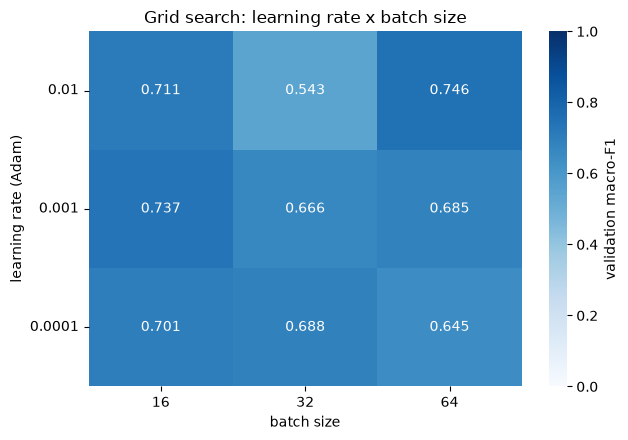

In [16]:
LRS = {1e-2: '1e-2', 1e-3: '1e-3', 1e-4: '1e-4'}
BATCHES = [16, 32, 64]
REUSED = {(1e-3, 32): 'abl_baseline_s1', (1e-2, 32): 'abl_lr1e-2', (1e-4, 32): 'abl_lr1e-4', (1e-3, 64): 'abl_batch64'}

GRID = {}   # name: (group, change, model settings, training settings), same format as ABLATIONS
for lr, lr_name in LRS.items():
    for batch in BATCHES:
        name = REUSED.get((lr, batch), f'grid_lr{lr_name}_b{batch}')
        GRID[name] = ('grid search', f'Adam, lr {lr_name}, batch {batch}', {}, {'lr': lr, 'batch': batch})
        if name.startswith('grid_'):   # the 4 reused runs are already trained
            utils.train_cnn(name, {}, {'lr': lr, 'batch': batch}, CONFIG['ablation_epochs'],
                            group='grid search', change=GRID[name][1])
            utils.clear()

grid = pd.DataFrame([{'model': n, 'lr': v[3]['lr'], 'batch': v[3]['batch']} for n, v in GRID.items()])
grid['val_macro_f1'] = utils.bench_table().loc[grid.model, 'val_macro_f1'].to_numpy()
utils.plot_grid_search(grid);

### 4.3 Comparative benchmark table

All the runs of 4.1 and 4.2 in one table:


- **parameters**: total number of weights of the model
- **receptive field**: size of the input region that one value of the last feature map depends on. For each conv / pool layer: $rf_{l} = rf_{l-1} + (k_l - 1) \times j_{l-1}$ and $j_l = j_{l-1} \times s_l$, where $k$ is the kernel size, $s$ the stride and $j$ the distance in input pixels between two neighbouring values of the feature map. The baseline sees 22 px of the 160x160 crop; global average pooling then combines all positions.
- **delta**: validation macro-F1 minus the mean of the 3 baseline seeds
- **generalization gap**: training accuracy (measured without augmentation and dropout) minus validation accuracy. A big gap means overfitting.
- **best epoch**: epoch with the lowest validation loss (the saved checkpoint)
- **latency**: inference time for one image

The last plot is the number-of-epochs experiment: train and validation curves over 30 epochs without early stopping, with the epoch of the lowest validation loss (where early stopping keeps the weights).

Baseline validation macro-F1 over 3 seeds: mean 0.714, range 0.666 to 0.751


,group,change,parameters,receptive_field,val_acc,val_macro_f1,delta,effect,unsafe_recall,train_acc,gap,best_epoch,seconds_per_epoch,latency_ms
model,,,,,,,,,,,,,,
abl_baseline_s1,baseline,Baseline (seed 1),53716,22.0,0.675,0.666,-0.048,baseline,0.680,0.601,-0.073,3.0,20.856,4.063
abl_baseline_s2,baseline,Baseline (seed 2),53716,22.0,0.729,0.726,0.011,baseline,0.764,0.682,-0.047,12.0,19.547,4.452
abl_baseline_s3,baseline,Baseline (seed 3),53716,22.0,0.753,0.751,0.037,baseline,0.745,0.717,-0.036,15.0,19.637,5.326
abl_blocks2,architecture,2 conv blocks,11572,10.0,0.561,0.558,-0.157,worse,0.589,0.519,-0.042,4.0,16.712,2.830
abl_blocks4,architecture,4 conv blocks,220948,46.0,0.831,0.832,0.118,better,0.812,0.782,-0.050,15.0,21.413,6.459
abl_kernel5,architecture,5x5 kernels,147028,36.0,0.678,0.675,-0.040,within noise,0.739,0.601,-0.077,3.0,24.011,7.656
abl_stride2,architecture,Stride-2 conv instead of max-pool,53716,15.0,0.745,0.740,0.026,within noise,0.741,0.696,-0.049,15.0,9.095,1.933
abl_no_bn,architecture,No BatchNorm,53044,22.0,0.651,0.648,-0.066,worse,0.714,0.644,-0.007,14.0,9.085,2.644
abl_flatten,architecture,Flatten instead of global avg pooling,206932,22.0,0.812,0.802,0.087,better,0.824,0.813,0.001,15.0,19.441,3.650


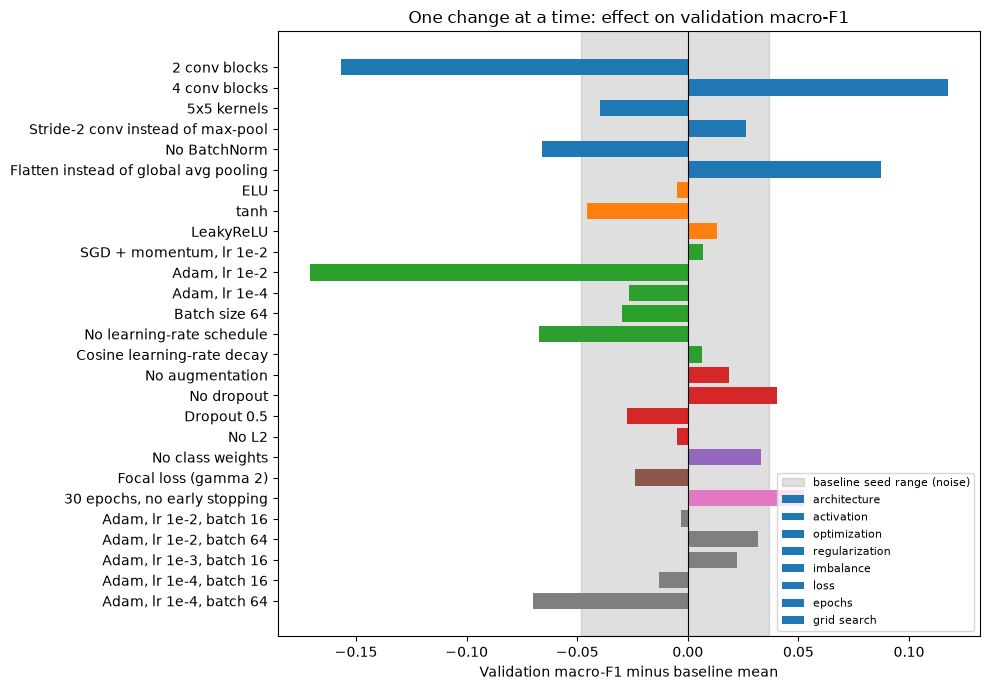

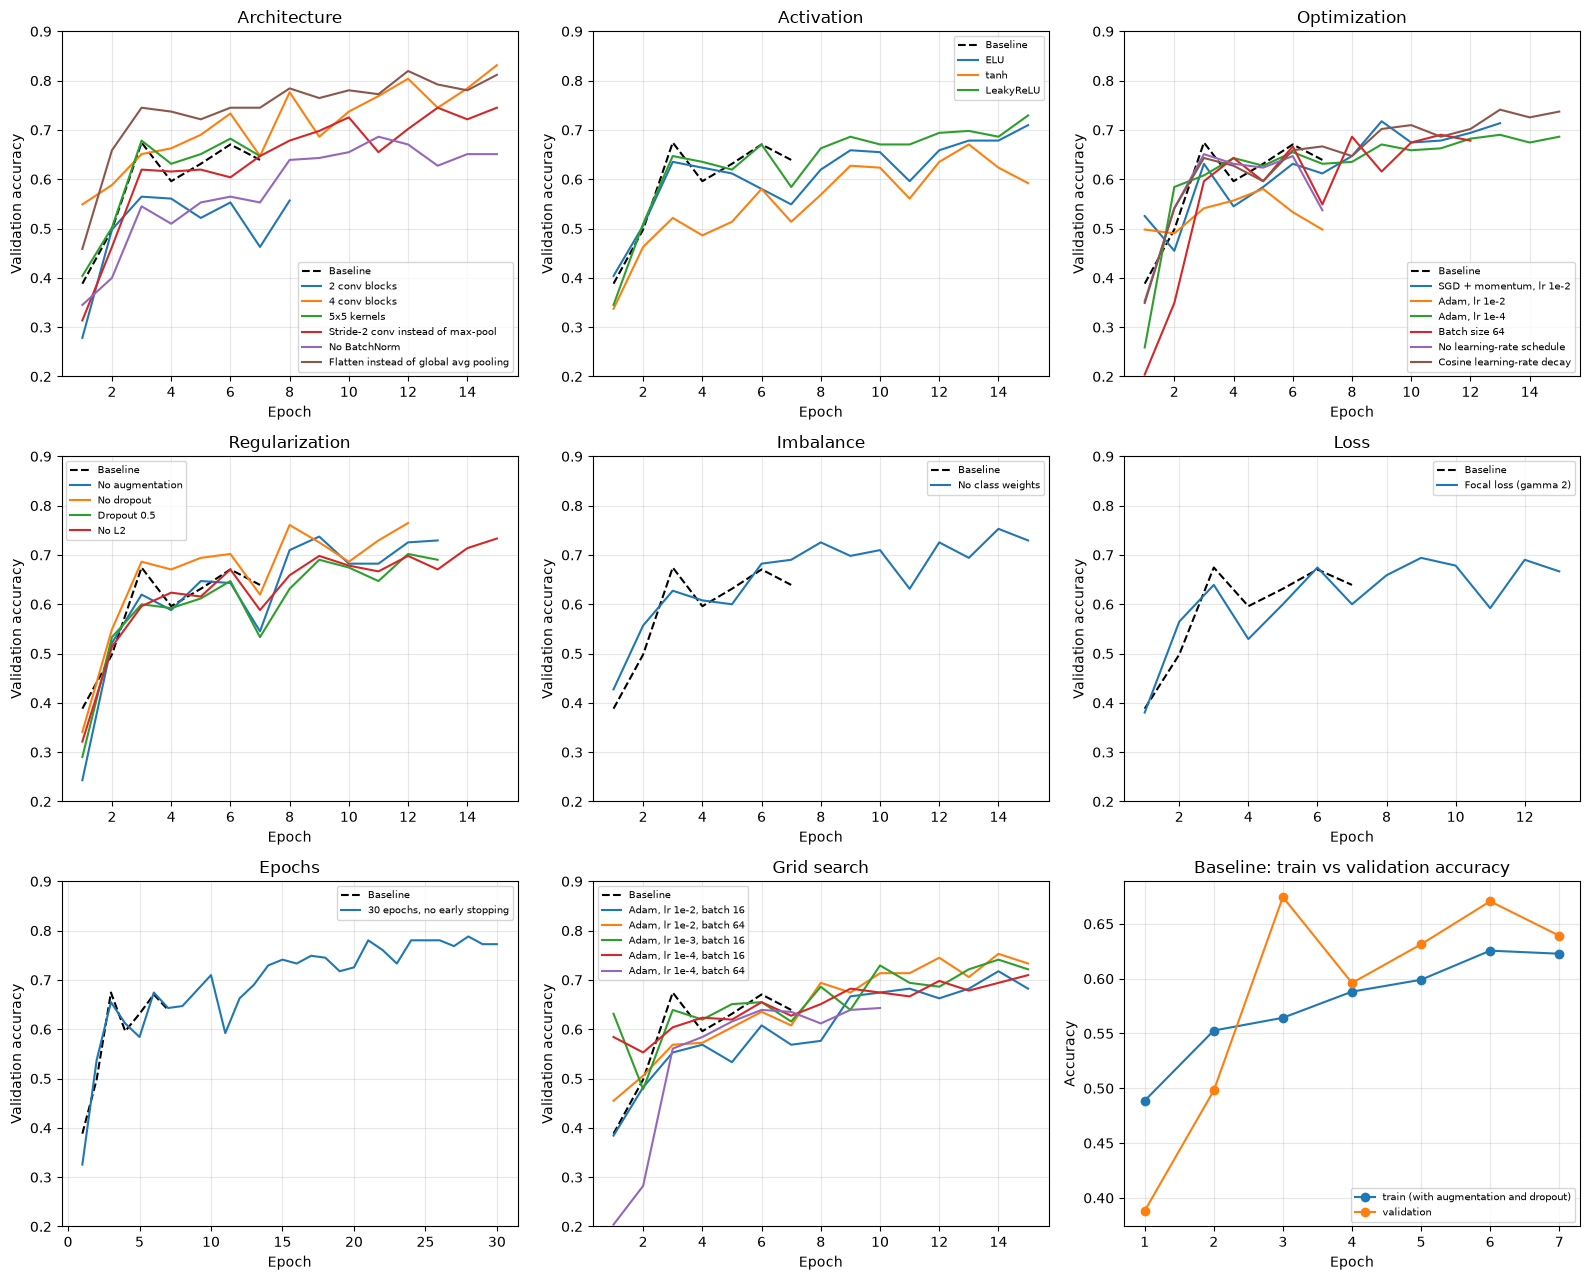

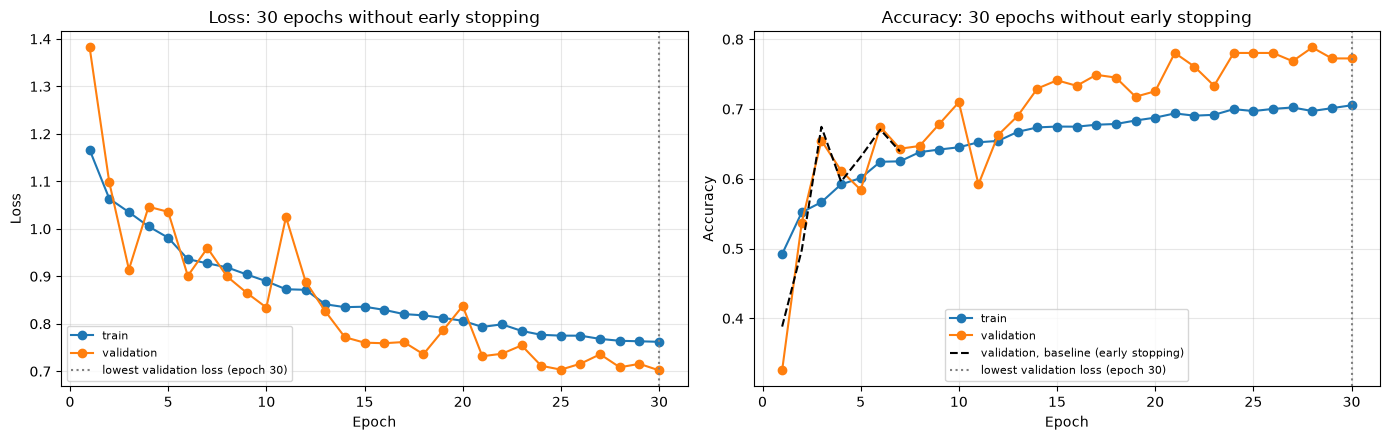

In [17]:
# Results table: every change compared with the mean of the three baseline seeds
# all runs of 4.1 + the new runs of the grid search
EXPERIMENTS = {**ABLATIONS, **{n: v for n, v in GRID.items() if n.startswith('grid_')}}
ABL, REF, LO, HI = utils.ablation_table(EXPERIMENTS)
print(f'Baseline validation macro-F1 over 3 seeds: mean {REF:.3f}, range {LO:.3f} to {HI:.3f}')

ABL_COLS = ['group', 'change', 'parameters', 'receptive_field', 'val_acc', 'val_macro_f1', 'delta', 'effect',
            'unsafe_recall', 'train_acc', 'gap', 'best_epoch', 'seconds_per_epoch', 'latency_ms']
ABL[ABL_COLS].to_csv(utils.RESULTS / 'ablation_results.csv')
display(ABL[ABL_COLS].round(3))

utils.plot_ablation_summary(ABL, REF, LO, HI)   # change in macro-F1 per experiment, seed range shaded
utils.plot_ablation_curves(ABL)                 # validation accuracy per epoch, one panel per group
utils.plot_epochs('abl_epochs30')               # number of epochs: 30 epochs without early stopping

### 4.4 Final model: combination of the best settings

We keep every change of 4.1 and 4.2 that was *better* than the baseline seed range. When two of them set the same option (for example a learning rate from 4.1 and a learning rate / batch size pair from the grid), we keep the better one. If no change is clearly better, every change with a positive mean difference is used instead (the cell prints which rule was applied).

We train it for **30 epochs** (still with early stopping), because the combined model may need more epochs to converge. Its settings are saved in `results/best_cnn_config.json` and reused in section 5.4.

In [18]:
# Combine every change that beat the seed range (rule in utils.combine_winners)
BEST_MODEL_KW, BEST_TRAIN_KW, BEST_CHANGES = utils.combine_winners(ABL, EXPERIMENTS)
print('Combined changes:', BEST_CHANGES or 'none, baseline settings with a longer budget')
(utils.RESULTS / 'best_cnn_config.json').write_text(json.dumps(
    {'changes': BEST_CHANGES, 'model': BEST_MODEL_KW, 'train': {**utils.BASE_TRAIN, **BEST_TRAIN_KW}}, indent=2))

best_cnn = utils.train_cnn('07_cnn_best', BEST_MODEL_KW, BEST_TRAIN_KW, CONFIG['best_cnn_epochs'], group='combined',
                           change=' + '.join(BEST_CHANGES) or 'baseline, 30 epochs')
utils.clear()

cmp = utils.bench_table().loc[['abl_baseline_s1', '07_cnn_best'],
                              ['parameters', 'val_acc', 'val_macro_f1', 'unsafe_recall', 'train_acc', 'gap',
                               'best_epoch', 'seconds_per_epoch']]
cmp.loc['baseline (mean of 3 seeds)'] = ABL.loc[ABL.group == 'baseline', cmp.columns].mean()
display(cmp.round(3))

Combined changes: ['4 conv blocks', 'Flatten instead of global avg pooling', '30 epochs, no early stopping', 'No dropout']
07_cnn_best: loaded trained model from ../Checkpoints/07_cnn_best.keras
07_cnn_best {'model': '07_cnn_best', 'training_seconds': 655.81, 'accuracy': 0.886, 'macro_f1': 0.882, 'balanced_accuracy': 0.888, 'unsafe_recall': 0.884}


,parameters,val_acc,val_macro_f1,unsafe_recall,train_acc,gap,best_epoch,seconds_per_epoch
model,,,,,,,,
abl_baseline_s1,53716,0.675,0.666,0.680,0.601,-0.073,3.0,20.856
07_cnn_best,296980,0.886,0.882,0.884,0.929,0.043,25.0,21.860
baseline (mean of 3 seeds),53716,0.719,0.714,0.730,0.667,-0.052,10.0,20.013


## Observations (hyperparameter tuning)

- *To be completed with the results of the GPU run:* per group (architecture, activation, optimization, regularization, class weights), which changes are outside the seed range.
- *To be completed:* grid search, best learning rate / batch size pair and how the two interact.
- *To be completed:* number of epochs, where the validation loss is lowest and what happens after it.
- *To be completed:* focal loss vs cross-entropy, in particular on unsafe recall.
- *To be completed:* combined CNN vs baseline (macro-F1, gap, best epoch).

## 5. Transfer learning

With about 11,000 crops, a network trained from scratch must learn low-level features (edges, colours, textures) from very little data. A backbone pre-trained on **ImageNet** (1.28M images, 1000 classes) has already learned them (Lecture 05).

**Why MobileNetV2:** VGG16 has about 138M parameters and ResNet50 25.6M, MobileNetV2 only 2.3M (backbone), which made fine-tuning possible on a CPU. ImageNet weights exist for 160x160 inputs, and its inverted-residual blocks with depthwise-separable convolutions are an example of the advanced architectures of the course (Sandler et al., 2018).

**Architecture:** input → augmentation → rescaling to [-1, 1] → MobileNetV2 backbone (`include_top=False`) → global average pooling → dense(128, ReLU) → dropout(0.4) → dense(4, softmax).

| setup | what is trained | learning rate |
|---|---|---|
| **frozen** (feature extraction, 5.1) | only the new head, backbone frozen (`trainable = False`) | 1e-3 |
| **fine-tune last 30** (5.2) | last 30 backbone layers + head, starting from the frozen model | 1e-4 (reduced) |
| **fine-tune all** (5.3) | the whole backbone + head, starting from the frozen model | 1e-4 (reduced) |

The fine-tuning uses a **10x smaller learning rate**, so the pre-trained filters are only slightly adapted and not destroyed by big updates. **BatchNorm layers stay frozen**: small batches would give noisy statistics that overwrite the ImageNet ones.

In 5.4 the 3 setups and our best CNN from scratch are trained again with **the same recipe** (one stage, 10 epochs), with **10% and 100%** of the training images, to compare **convergence speed** and **data efficiency**.

### 5.1 Frozen backbone

In [19]:
# Stage A: MobileNetV2 (ImageNet) with a new head; the backbone stays frozen (utils.build_transfer)
transfer, backbone = utils.build_transfer()
transfer = utils.run('05_transfer_frozen', transfer, 1e-3, CONFIG['transfer_epochs'],
                     group='transfer', change='Frozen backbone, new head')

05_transfer_frozen: loaded trained model from ../Checkpoints/05_transfer_frozen.keras
05_transfer_frozen {'model': '05_transfer_frozen', 'training_seconds': 1573.05, 'accuracy': 0.855, 'macro_f1': 0.849, 'balanced_accuracy': 0.859, 'unsafe_recall': 0.846}


### 5.2 Fine-tune the last 30 layers

The last layers of a pre-trained network hold the most task-specific features, so they are the ones worth adapting. The model is compiled again after the trainable flags change.

In [20]:
# Stage B: unfreeze only the last 30 backbone layers; their BatchNorm layers stay frozen
utils.unfreeze(backbone, last=30)

# run() recompiles the model (required after changing trainable flags) with a 10x lower learning rate
transfer = utils.run('06_transfer_finetuned', transfer, 1e-4, CONFIG['fine_tune_epochs'],
                     group='transfer', change='Fine-tune last 30 backbone layers')
print('Trainable parameters:', utils.count_trainable(transfer))

06_transfer_finetuned: loaded trained model from ../Checkpoints/06_transfer_finetuned.keras
06_transfer_finetuned {'model': '06_transfer_finetuned', 'training_seconds': 1431.23, 'accuracy': 0.898, 'macro_f1': 0.896, 'balanced_accuracy': 0.9, 'unsafe_recall': 0.907}
Trainable parameters: 1675204


### 5.3 Fine-tune all layers

Fine-tuning only the last 30 layers assumes that the early ImageNet filters already suit PPE crops. Unfreezing the whole backbone tests this: it can adapt more, but it trains almost all of the 2.3M backbone parameters on 11,000 crops, so it can also overfit more. It starts from the same frozen model as 5.2.

In [21]:
# Stage C: start again from the Stage A (frozen) model and unfreeze the whole backbone, BatchNorm excluded
utils.set_seed(SEED)
full = utils.load('05_transfer_frozen')
utils.unfreeze(utils.get_backbone(full))

full = utils.run('08_transfer_finetune_all', full, 1e-4, CONFIG['fine_tune_epochs'],
                 group='transfer', change='Fine-tune all backbone layers')
print('Trainable parameters:', utils.count_trainable(full))
display(utils.bench_table().loc[['05_transfer_frozen', '06_transfer_finetuned', '08_transfer_finetune_all'],
                                ['change', 'parameters', 'trainable_parameters', 'val_acc', 'val_macro_f1',
                                 'unsafe_recall', 'train_acc', 'gap', 'latency_ms']].round(3))

08_transfer_finetune_all: loaded trained model from ../Checkpoints/08_transfer_finetune_all.keras
08_transfer_finetune_all {'model': '08_transfer_finetune_all', 'training_seconds': 254.67, 'accuracy': 0.878, 'macro_f1': 0.87, 'balanced_accuracy': 0.871, 'unsafe_recall': 0.875}
Trainable parameters: 2354244


,change,parameters,trainable_parameters,val_acc,val_macro_f1,unsafe_recall,train_acc,gap,latency_ms
model,,,,,,,,,
05_transfer_frozen,"Frozen backbone, new head",2422468,164484,0.855,0.849,0.846,0.842,-0.013,14.946
06_transfer_finetuned,Fine-tune last 30 backbone layers,2422468,1675204,0.898,0.896,0.907,0.917,0.019,14.699
08_transfer_finetune_all,Fine-tune all backbone layers,2422468,2354244,0.878,0.870,0.875,0.917,0.039,14.613


### 5.4 Setups compared: convergence speed and data efficiency

5.1 to 5.3 build on each other, so their epochs and starting points are different. To compare the setups fairly, each one is trained again **in one stage with the same recipe**: a new head on MobileNetV2 with 0, the last 30 or all backbone layers trainable, against our best CNN from scratch (settings of 4.4).

| setup | what is trained | learning rate |
|---|---|---|
| CNN from scratch | all layers, random init | as in 4.4 |
| frozen | new head only | 1e-3 |
| fine-tune last 30 | last 30 backbone layers + head | 1e-4 |
| fine-tune all | the whole network (BatchNorm frozen) | 1e-4 |

4 setups x 2 train fractions = 8 runs of 10 epochs. The 10% subset is drawn **by parent image** (crops of one image stay together) and must contain all 4 classes.

In [22]:
# Settings of the combined best CNN chosen in 4.4 (saved in results/best_cnn_config.json)
BEST_MODEL_KW, BEST_TRAIN_KW = utils.load_best_cnn_config()

# 10% of the training images, drawn by parent image so that crops of one image stay together
SMALL_ROWS, n_small, n_images = utils.small_subset(CONFIG['small_fraction'])
print(f'Small subset: {n_small} of {n_images} images, {len(SMALL_ROWS):,} crops, '
      f'per class {np.bincount(DF.label[SMALL_ROWS], minlength=4).tolist()}')

# setup: (label, learning rate); 'scratch' uses the settings of the combined CNN from 4.4
SETUPS = {'scratch': ('CNN from scratch', None), 'frozen': ('Frozen', 1e-3),
          'last30': ('Fine-tune last 30', 1e-4), 'all': ('Fine-tune all', 1e-4)}
TL_RUNS = {}   # name: (setup label, % of data, learning rate)
for pct, rows in [(10, SMALL_ROWS), (100, utils.TRAIN_ROWS)]:
    for setup, (label, lr) in SETUPS.items():
        name = f'tl_{setup}_{pct}pct'
        if setup == 'scratch':
            lr = {**utils.BASE_TRAIN, **BEST_TRAIN_KW}['lr']
            utils.train_cnn(name, BEST_MODEL_KW, BEST_TRAIN_KW, CONFIG['tl_compare_epochs'], rows=rows,
                            group='transfer comparison', change=f'{label}, {pct}% data')
        else:
            utils.set_seed(SEED)
            utils.run(name, utils.make_transfer(setup), lr, CONFIG['tl_compare_epochs'],
                      train=utils.make_ds('train', True, rows=rows), weights=utils.class_weights_for(rows),
                      train_rows=rows, group='transfer comparison', change=f'{label}, {pct}% data')
        TL_RUNS[name] = (label, pct, lr)
        utils.clear()

Small subset: 240 of 2400 images, 1,143 crops, per class [278, 199, 293, 373]
tl_scratch_10pct: loaded trained model from ../Checkpoints/tl_scratch_10pct.keras
tl_scratch_10pct {'model': 'tl_scratch_10pct', 'training_seconds': 27.34, 'accuracy': 0.459, 'macro_f1': 0.485, 'balanced_accuracy': 0.518, 'unsafe_recall': 0.595}
tl_frozen_10pct: loaded trained model from ../Checkpoints/tl_frozen_10pct.keras
tl_frozen_10pct {'model': 'tl_frozen_10pct', 'training_seconds': 24.88, 'accuracy': 0.753, 'macro_f1': 0.745, 'balanced_accuracy': 0.751, 'unsafe_recall': 0.696}
tl_last30_10pct: loaded trained model from ../Checkpoints/tl_last30_10pct.keras
tl_last30_10pct {'model': 'tl_last30_10pct', 'training_seconds': 30.21, 'accuracy': 0.804, 'macro_f1': 0.797, 'balanced_accuracy': 0.803, 'unsafe_recall': 0.753}
tl_all_10pct: loaded trained model from ../Checkpoints/tl_all_10pct.keras
tl_all_10pct {'model': 'tl_all_10pct', 'training_seconds': 45.93, 'accuracy': 0.816, 'macro_f1': 0.808, 'balanced_accu

- **convergence speed:** first epoch where the validation accuracy reaches 70% and 80%. Pre-trained models start from useful features, so they should get there after very few epochs.
- **data efficiency:** validation macro-F1 with 10% vs 100% of the training images. A small drop means the method needs less data.

,setup,data,parameters,trainable_parameters,lr,peak_val_acc,epochs_to_70,epochs_to_80,val_acc,val_macro_f1,unsafe_recall,gap,seconds_per_epoch,latency_ms
model,,,,,,,,,,,,,,
tl_scratch_10pct,CNN from scratch,10%,296980,296260,0.001,0.459,NaN,NaN,0.459,0.485,0.595,-0.048,2.734,7.719
tl_frozen_10pct,Frozen,10%,2422468,164484,0.001,0.753,2.0,NaN,0.753,0.745,0.696,0.097,2.764,16.554
tl_last30_10pct,Fine-tune last 30,10%,2422468,1675204,0.000,0.804,2.0,8.0,0.804,0.797,0.753,0.119,3.021,16.257
tl_all_10pct,Fine-tune all,10%,2422468,2354244,0.000,0.824,3.0,6.0,0.816,0.808,0.807,0.069,4.593,15.240
tl_scratch_100pct,CNN from scratch,100%,296980,296260,0.001,0.827,3.0,6.0,0.827,0.819,0.846,-0.009,21.251,8.472
tl_frozen_100pct,Frozen,100%,2422468,164484,0.001,0.831,1.0,5.0,0.831,0.826,0.835,-0.001,13.923,15.299
tl_last30_100pct,Fine-tune last 30,100%,2422468,1675204,0.000,0.878,1.0,1.0,0.875,0.868,0.878,0.024,16.515,17.293
tl_all_100pct,Fine-tune all,100%,2422468,2354244,0.000,0.867,1.0,1.0,0.820,0.814,0.807,-0.001,30.414,18.124


data,10%,100%,drop
setup,,,
CNN from scratch,0.485,0.819,0.334
Frozen,0.745,0.826,0.081
Fine-tune last 30,0.797,0.868,0.071
Fine-tune all,0.808,0.814,0.006


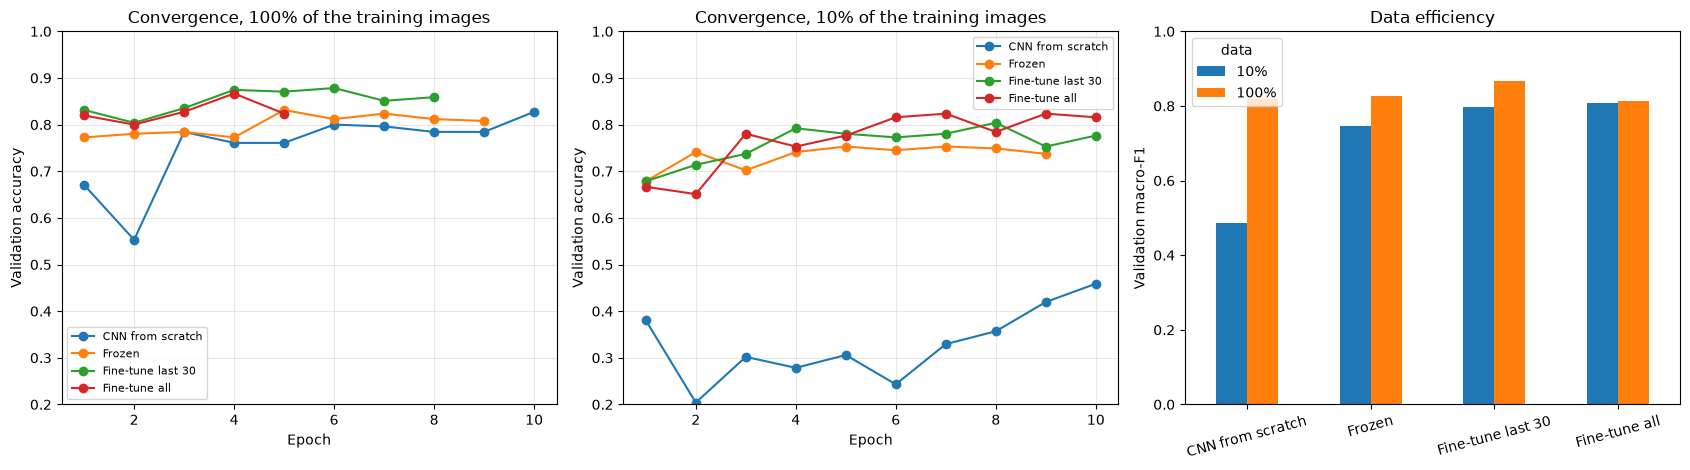

In [23]:
# Benchmark + convergence speed (epochs to 70% / 80% validation accuracy) and data efficiency
TLC, EFF = utils.transfer_table(TL_RUNS, [label for label, _ in SETUPS.values()])
TLC_COLS = ['setup', 'data', 'parameters', 'trainable_parameters', 'lr', 'peak_val_acc', 'epochs_to_70', 'epochs_to_80',
            'val_acc', 'val_macro_f1', 'unsafe_recall', 'gap', 'seconds_per_epoch', 'latency_ms']
TLC[TLC_COLS].to_csv(utils.RESULTS / 'transfer_comparison.csv')
display(TLC[TLC_COLS].round(3))
display(EFF.round(3))
utils.plot_transfer_comparison(TLC, EFF)

## Observations (transfer learning)

- **Frozen backbone:** after a **single epoch** the validation accuracy is already 0.765, higher than the best epoch of any CNN from scratch (0.737). Final macro-F1 **0.849** (+0.15 over the best scratch CNN), unsafe recall 0.846. Train and validation accuracy are almost equal (about 0.86), so no overfitting.
- **Fine-tune last 30 layers:** macro-F1 **0.896** (+0.047), unsafe recall 0.907, with 1.68M trainable parameters. The fine-tuning was unstable: at epoch 4 the validation loss jumped to 0.908; ReduceLROnPlateau halved the learning rate and epoch 5 gave the best result (validation loss 0.409, accuracy 0.898). After that the model overfitted (train accuracy 0.95, validation 0.86) and the checkpoint kept epoch 5. Fine-tuning only pays off with a low learning rate, an adaptive schedule and checkpointing.
- *To be completed with the results of the GPU run.* (fine-tune all vs last 30)
- *To be completed: convergence speed, data efficiency (10% vs 100%) and cost of each setup.*

## 6. Integration of course topics

| topic | where it is used | section |
|---|---|---|
| Perceptron and MLP (Lectures 02-03) | baseline dense network | 3.1 |
| Activation functions | ReLU, ELU, tanh and LeakyReLU compared one at a time; softmax output | 3, 4.1 |
| Loss functions (Lecture 04) | sparse categorical cross-entropy, weighted by class against the imbalance; focal loss compared with it | 2.4, 3, 4.1 |
| Optimization algorithms (Lecture 04) | Adam vs SGD with momentum; learning rate and batch size, one at a time and as a grid; number of epochs; plateau / cosine / no learning-rate schedule | 3, 4.1, 4.2 |
| Regularization | dropout, L2, data augmentation, early stopping; each removed or changed one at a time, with the generalization gap measured | 3, 4.1, 5 |
| Normalization | pixel scaling to [0, 1] and [-1, 1]; BatchNorm in every conv block, and one run without it | 2.4, 3.2, 4.1 |
| CNN architecture (Lecture 06) | convolution, pooling, global average pooling; depth, kernel size, stride vs pooling, receptive field | 3.2, 4.1 |
| Advanced architectures | MobileNetV2: depthwise-separable convolutions, inverted residuals | 5 |
| Transfer learning (Lecture 05) | frozen feature extraction, partial and full fine-tuning, reduced learning rate, 10% vs 100% of the data | 5 |
| Hyperparameter tuning | one change at a time with a seed-noise floor, grid search over learning rate x batch size, then a combined best model | 4 |
| Evaluation metrics | macro-F1, balanced accuracy, per-class precision and recall, confusion matrix | 7 |

**Not applied:**
- **Recurrent networks (Lecture 07)** model sequences; these images are independent and have no temporal order.

## 7. Evaluation and interpretation

The final model is chosen by **validation macro-F1** (unsafe recall as tie-break) among all experiments, and only its best checkpoint is evaluated **once** on the held-out test set. "Unsafe recall" is the recall of the NO-Hardhat and NO-Safety Vest regions, not of violations per worker. Accuracy alone can hide rare but costly misses, so per-class metrics are reported too.

### 7.1 Comparison of all models (validation)

The table ranks **every experiment** of the notebooks 01 to 03 by validation macro-F1; the first one is the final model. The second table puts the main models side by side: accuracy against size (parameters), speed (latency) and overfitting (generalization gap).

In [24]:
# All experiments ranked by validation macro-F1 (tie-break: unsafe-class recall). The final model is chosen from all of them.
VAL = utils.results_table()
print(f'{len(VAL)} experiments; top 10:')
display(VAL.head(10))

# Main models side by side: accuracy vs size, speed and over-fitting
BENCH = utils.bench_table()
MAIN = [m for m in ['01_mlp', '02_cnn_relu', '03_cnn_elu_dropout', '07_cnn_best',
                    '05_transfer_frozen', '06_transfer_finetuned', '08_transfer_finetune_all'] if m in BENCH.index]
MAIN_COLS = ['change', 'parameters', 'trainable_parameters', 'val_acc', 'val_macro_f1', 'unsafe_recall',
             'train_acc', 'gap', 'latency_ms', 'device']
BENCH.loc[MAIN, MAIN_COLS].to_csv(utils.RESULTS / 'main_models_benchmark.csv')
display(BENCH.loc[MAIN, MAIN_COLS].round(3))

45 experiments; top 10:


,model,training_seconds,accuracy,macro_f1,balanced_accuracy,unsafe_recall
35,06_transfer_finetuned,1431.23,0.898039,0.896061,0.899882,0.907191
33,07_cnn_best,655.81,0.886275,0.881713,0.887906,0.883779
36,08_transfer_finetune_all,254.67,0.878431,0.870452,0.870568,0.875418
43,tl_last30_100pct,132.12,0.874510,0.867761,0.875185,0.878344
34,05_transfer_frozen,1573.05,0.854902,0.848661,0.859151,0.845736
7,abl_blocks4,321.19,0.831373,0.831956,0.855107,0.811873
42,tl_frozen_100pct,125.31,0.831373,0.825968,0.836864,0.834866
41,tl_scratch_100pct,212.51,0.827451,0.818725,0.835179,0.845736
44,tl_all_100pct,152.07,0.819608,0.813699,0.819643,0.807274
40,tl_all_10pct,45.93,0.815686,0.807913,0.806755,0.807274


,change,parameters,trainable_parameters,val_acc,val_macro_f1,unsafe_recall,train_acc,gap,latency_ms,device
model,,,,,,,,,,
01_mlp,MLP baseline,1573508,1573508,0.573,0.568,0.574,0.600,0.028,0.709,CPU (first run)
02_cnn_relu,CNN (ReLU),53716,53380,0.702,0.696,0.778,0.681,-0.021,5.953,CPU (first run)
03_cnn_elu_dropout,CNN (ELU + dropout 0.45 + L2 5e-4 + lr 5e-4),53716,53380,0.694,0.689,0.692,0.654,-0.040,6.326,CPU (first run)
07_cnn_best,4 conv blocks + Flatten instead of global avg ...,296980,296260,0.886,0.882,0.884,0.929,0.043,5.364,GPU
05_transfer_frozen,"Frozen backbone, new head",2422468,164484,0.855,0.849,0.846,0.842,-0.013,14.946,CPU (first run)
06_transfer_finetuned,Fine-tune last 30 backbone layers,2422468,1675204,0.898,0.896,0.907,0.917,0.019,14.699,CPU (first run)
08_transfer_finetune_all,Fine-tune all backbone layers,2422468,2354244,0.878,0.870,0.875,0.917,0.039,14.613,GPU


**Validation macro-F1 and unsafe-class recall of the main models.** Unsafe recall is shown next to macro-F1 because a missed NO-Hardhat or NO-Safety Vest is the most costly error.

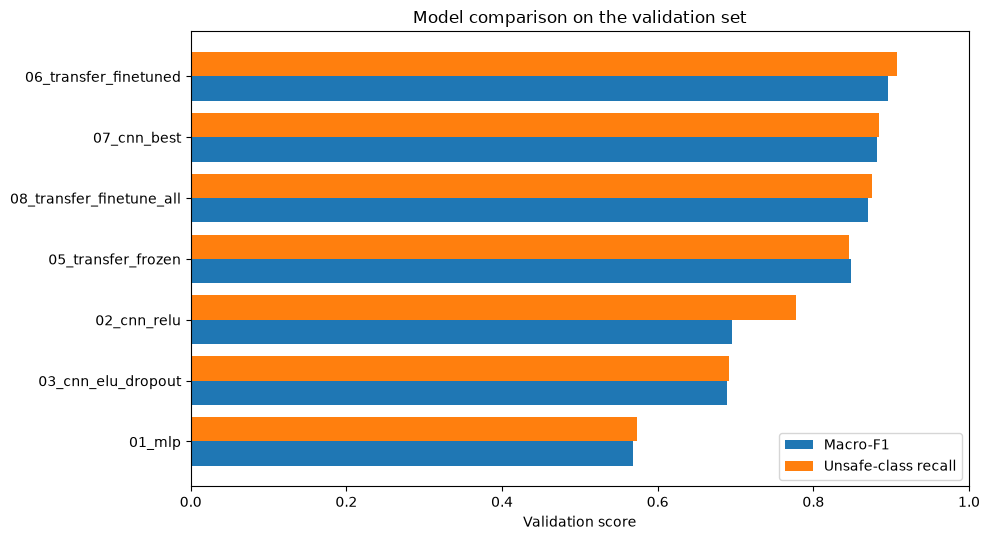

In [25]:
# Model comparison chart: validation macro-F1 and unsafe-class recall for the main models
utils.plot_model_comparison(BENCH, MAIN)

### 7.2 Test the chosen model on the unseen test data

We load back the **best checkpoint** of the chosen model (lowest validation loss), not the model of the last epoch.

{
  "chosen_model": "06_transfer_finetuned",
  "test_accuracy": 0.9144981412639405,
  "test_macro_f1": 0.9090691050906964,
  "test_balanced_accuracy": 0.920411504444524,
  "test_unsafe_recall": 0.9243170622480967,
  "number_test_crops": 269
}


,precision,recall,f1-score,support
Hardhat,0.922,0.931,0.927,102.000
NO-Hardhat,0.824,0.966,0.889,29.000
Safety Vest,0.902,0.902,0.902,61.000
NO-Safety Vest,0.958,0.883,0.919,77.000
accuracy,0.914,0.914,0.914,0.914
macro avg,0.901,0.920,0.909,269.000
weighted avg,0.917,0.914,0.915,269.000


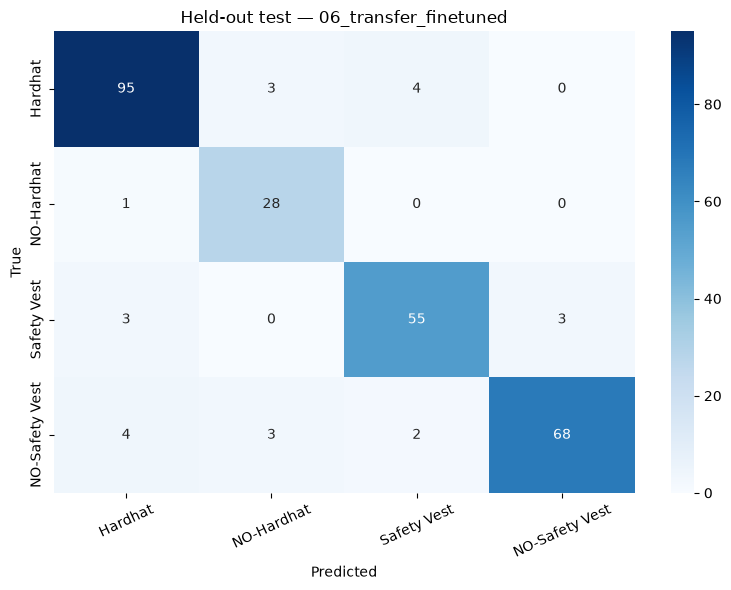

In [26]:
# Load the best checkpoint of the chosen model and score it ONCE on the held-out test set
chosen = str(VAL.iloc[0]['model'])
final_model, metrics, report, y_true, y_pred, proba = utils.final_test(chosen)
print(json.dumps(metrics, indent=2))
display(pd.DataFrame(report).T.round(3))
utils.plot_confusion_matrix(y_true, y_pred, 'Held-out test — ' + chosen)

### 7.3 Learning curves

Validation accuracy per epoch of the main models. The epoch budgets are different between stages (15 epochs from scratch, 8 to 15 for transfer learning, 30 for the combined CNN), and early stopping can end a run earlier.

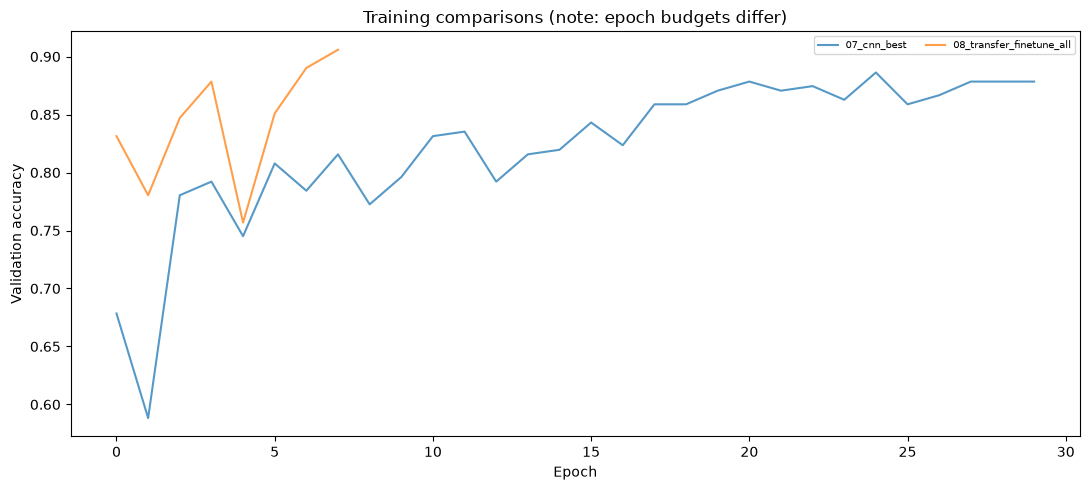

In [27]:
# Validation accuracy per epoch for the main models (epoch budgets differ between stages)
utils.plot_validation_curves(MAIN)

**Training vs validation loss of each main model.** When the training loss keeps going down while the validation loss goes up, the model starts to memorize the training crops (overfitting). The training loss also includes dropout, augmentation and L2, so it can be higher than the validation loss.

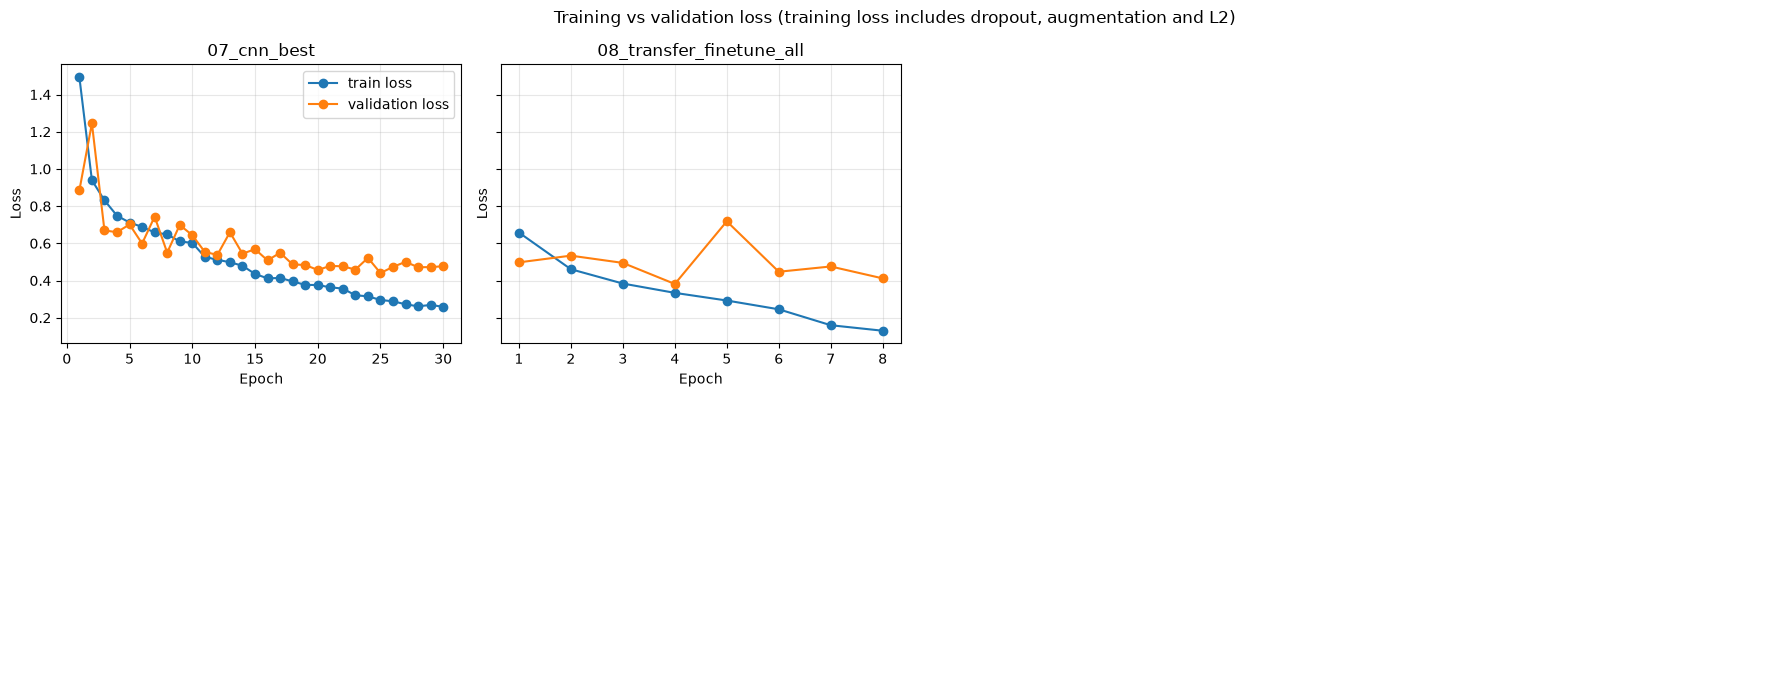

In [28]:
# Training vs validation loss for the main models: a widening gap signals over-fitting
utils.plot_loss_curves(MAIN)

### 7.4 Error analysis

Up to 12 misclassified test crops, with the confidence of the model.

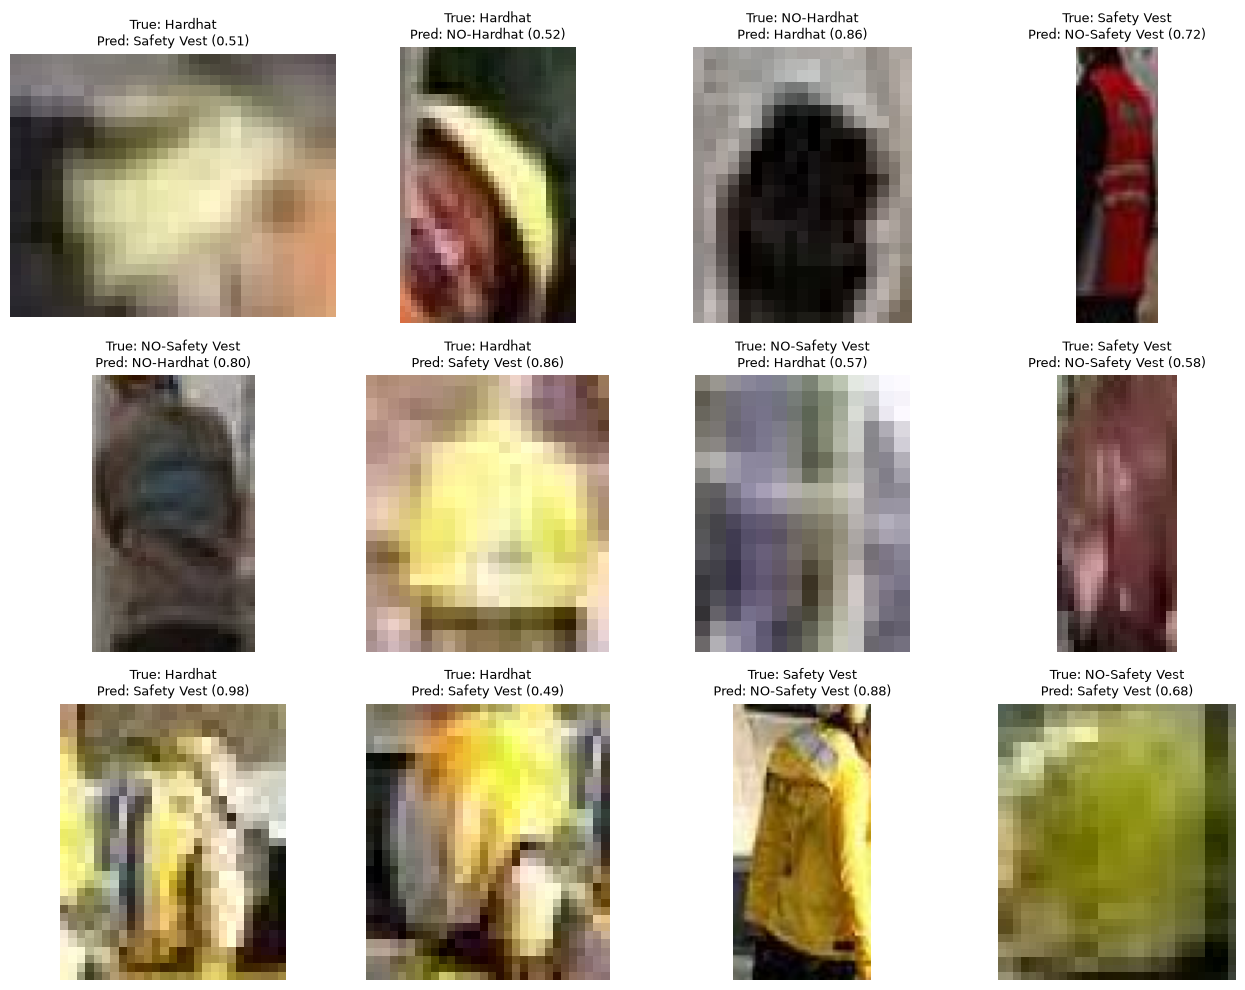

In [29]:
# Error gallery: up to 12 misclassified test crops with the model's confidence
utils.error_gallery(y_true, y_pred, proba)

# Export the final model and per-crop test predictions
final_model.save(utils.CKPT / 'final_ppe_classifier.keras')
pd.DataFrame({'true': y_true, 'pred': y_pred, 'confidence': proba.max(axis=1),
              'parent_image': DF[DF.split == 'test'].parent.values}).to_csv(utils.RESULTS / 'test_predictions.csv', index=False)

### 7.5 Challenges and solutions

| challenge | what was done | possible next step |
|---|---|---|
| CPU-only training in the first run (6.8 hours) | 160x160 images, a light backbone, early stopping, crops cached in memory; later experiments on a Colab GPU | |
| small validation and test sets (255 and 269 crops) | macro-F1 and balanced accuracy, 3-seed noise floor for the tuning experiments, one single test evaluation | cross-validation grouped by parent image, more labelled images |
| class imbalance (about 1.9x in training) | inverse-frequency class weights; focal loss tested as an alternative (4.1) | oversampling of the rare classes |
| leakage risk from the augmented export | image-level splits, crops kept inside their split, SHA-256 check | perceptual hashing, or the non-augmented dataset version |
| unstable fine-tuning | low learning rate, ReduceLROnPlateau, checkpointing | gradual unfreezing, cosine schedule |
| hard hat vs vest confusion on tiny crops | 10% padding for context | higher input resolution, minimum crop size at inference |

## Observations (evaluation)

- **Model ranking:** transfer learning (0.85-0.90 macro-F1) is far ahead of the CNNs from scratch (about 0.69-0.70) and the MLP (0.57). The fine-tuned MobileNetV2 (last 30 layers) is first on every metric. *To be updated with 07 and 08 after the GPU run.*
- **Test results:** accuracy **0.914**, macro-F1 **0.909**, balanced accuracy 0.920, unsafe recall **0.924** on 269 crops (23 errors). Slightly *higher* than on validation (0.898 / 0.896), so the model selection did not overfit the validation set.
- **NO-Hardhat:** 28 of 29 found (recall 0.966), but precision is only 0.824 because 6 crops of other classes were predicted as NO-Hardhat. For a safety screening tool, false alarms are the more acceptable error.
- **NO-Safety Vest:** precision 0.958, recall 0.883; 9 of 77 were missed, 4 of them predicted as Hardhat. This is the most important weakness of the model.
- **Hardhat vs Safety Vest** is the most common confusion (4 + 3 = 7 crops): both are usually bright yellow or orange, so colour alone is ambiguous. NO-Hardhat is never confused with Safety Vest (head region vs torso region).
- **Learning curves:** the transfer models start where the scratch models finish, and the scratch curves are noisy and still rising when their budget ends. The dip of the fine-tuned model at epoch 4 is the instability described in 5.2.
- **Errors:** most errors are **tiny, blurry crops** (a few dozen pixels before enlargement) where a yellow hard hat and a yellow vest look like the same patch of colour. Several errors have a **low confidence** (0.49-0.58), so a confidence threshold could send uncertain crops to a human reviewer. Some labels look ambiguous or wrong, so part of the remaining error comes from the annotations.

## 8. Conclusion

*To be updated with the results of 4.1-4.4 and 5.3-5.4 after the GPU run.*

**Answer to the research question: yes.** A MobileNetV2 pre-trained on ImageNet classifies PPE regions far more reliably than a dense network or a CNN trained from scratch, and it is also the best model on the unsafe classes.

| stage | best model | val macro-F1 | change |
|---|---|---:|---:|
| baseline | MLP | 0.568 | |
| step-by-step architecture | CNN (ReLU) | 0.696 | +0.128 |
| transfer learning, frozen | MobileNetV2 | 0.849 | +0.153 |
| transfer learning, fine-tuned | MobileNetV2 | **0.896** | +0.047 |
| **held-out test** | **fine-tuned MobileNetV2** | **0.909** | accuracy 0.914, unsafe recall 0.924 |

**Key findings:**
1. **Convolutions** gave the biggest architectural gain over the MLP, with 29x fewer parameters.
2. **Transfer learning** was the single biggest improvement. Fine-tuning added more, but only with a low learning rate and checkpointing.

**Threats to validity:** version 27 contains augmented images, so near-duplicate scenes across splits cannot be fully excluded. The evaluation sets are small and crops of the same image are correlated. Some classes are visually ambiguous and some labels are noisy. No detection metric (mAP) or per-worker evaluation was made, and no claim is made about real-world safety without field validation.

**Future work:** train a YOLO detector on the non-augmented version and compare per-class mAP; link PPE to individual workers; test on images from another construction site; calibrate the confidence scores; keep a human in the loop.

## References

- **MLAI 504 course lectures:** 01 Introduction to Machine Learning and Deep Learning; 02 Neural Networks (part 1: introduction, part 2: perceptron); 03 MLP; 04 Cost and Optimization; 05 Transfer Learning; 06 CNN; 07 RNN (discussed but not applied).
- Roboflow Universe Projects, *Construction Site Safety*, dataset version 27, CC BY 4.0. https://universe.roboflow.com/roboflow-universe-projects/construction-site-safety/dataset/27
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted Residuals and Linear Bottlenecks. *CVPR*.
- Howard, A. et al. (2017). MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications. arXiv:1704.04861.
- Simonyan, K., & Zisserman, A. (2015). Very Deep Convolutional Networks for Large-Scale Image Recognition. *ICLR*.
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep Residual Learning for Image Recognition. *CVPR*.
- Lin, T.-Y., Goyal, P., Girshick, R., He, K., & Dollar, P. (2017). Focal Loss for Dense Object Detection. *ICCV*.
- Kingma, D. P., & Ba, J. (2015). Adam: A Method for Stochastic Optimization. *ICLR*.
- Srivastava, N. et al. (2014). Dropout: A Simple Way to Prevent Neural Networks from Overfitting. *JMLR*, 15.
- Ioffe, S., & Szegedy, C. (2015). Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift. *ICML*.
- Clevert, D.-A., Unterthiner, T., & Hochreiter, S. (2016). Fast and Accurate Deep Network Learning by Exponential Linear Units (ELUs). *ICLR*.
- TensorFlow / Keras documentation: https://www.tensorflow.org/api_docs/python/tf/keras
- scikit-learn, classification metrics: https://scikit-learn.org/stable/modules/model_evaluation.html

## Appendix: Demo, load a saved checkpoint and test it

Used during the defense:

1. choose any saved checkpoint (`.keras`) from the `Checkpoints/` folder
2. load the model with its weights
3. run inference on random crops of the **test set**
4. evaluate it on the full test set

No training here, every cell runs in a few seconds. The official test result of the project is the one of section 7; this demo only shows the models at work.

### A.1 Available checkpoints

In [30]:
checkpoint_names = sorted(p.stem for p in utils.CKPT.glob('*.keras'))
for name in checkpoint_names:
    print(name)

01_mlp
02_cnn_relu
03_cnn_elu_dropout
05_transfer_frozen
06_transfer_finetuned
07_cnn_best
08_transfer_finetune_all
abl_baseline_s1
abl_baseline_s2
abl_baseline_s3
abl_batch64
abl_blocks2
abl_blocks4
abl_cosine
abl_dropout0
abl_dropout05
abl_elu
abl_epochs30
abl_flatten
abl_focal
abl_kernel5
abl_leaky_relu
abl_lr1e-2
abl_lr1e-4
abl_no_aug
abl_no_bn
abl_no_cw
abl_no_l2
abl_no_sched
abl_sgd
abl_stride2
abl_tanh
final_ppe_classifier
grid_lr1e-2_b16
grid_lr1e-2_b64
grid_lr1e-3_b16
grid_lr1e-4_b16
grid_lr1e-4_b64
tl_all_100pct
tl_all_10pct
tl_frozen_100pct
tl_frozen_10pct
tl_last30_100pct
tl_last30_10pct
tl_scratch_100pct
tl_scratch_10pct


### A.2 Load a checkpoint

`final_ppe_classifier` is the model chosen. Any other name of the list above works too.

In [31]:
CHECKPOINT_NAME = 'final_ppe_classifier'

model = utils.load(CHECKPOINT_NAME)
print('model:', model.name)
print('parameters:', f'{model.count_params():,}', '| trainable:', f'{utils.count_trainable(model):,}')

model: mobilenetv2_ppe
parameters: 2,422,468 | trainable: 1,675,204


### A.3 Inference on random test crops

Wrong predictions are shown in red, with the confidence of the model.

Correct: 16/16


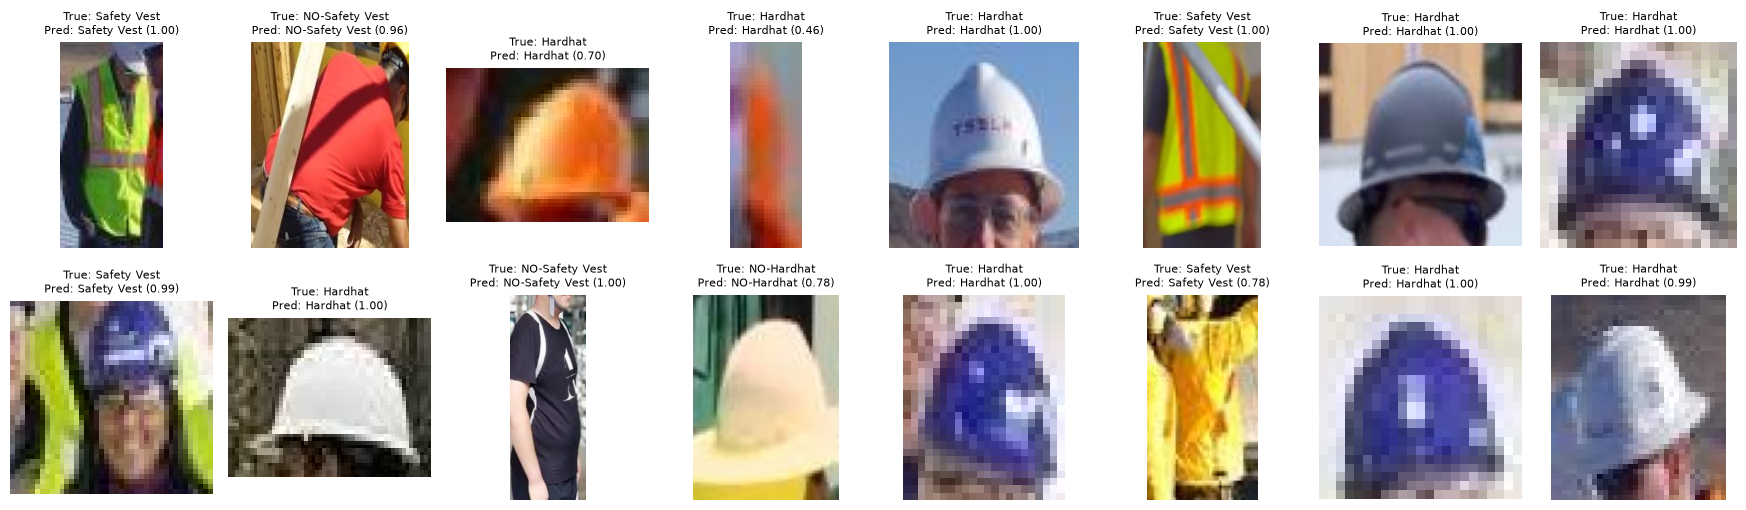

In [32]:
N_CROPS = 16
rows = DF[DF.split == 'test'].sample(N_CROPS)
images = utils.CROPS[rows.index].astype('float32') / 255.   # same scaling as during training
proba = model.predict(images, verbose=0)
y_true, y_pred = rows.label.to_numpy(), proba.argmax(1)

print(f'Correct: {(y_true == y_pred).sum()}/{N_CROPS}')
utils.show_predictions(rows, y_true, y_pred, proba)

### A.4 Evaluation on the full test set (269 crops)

In [33]:
y_true, proba = utils.predict_split(model, 'test')
y_pred = proba.argmax(1)
print(f'Accuracy of the model on the {len(y_true)} test crops: {100 * (y_true == y_pred).mean():.2f} %')
print(classification_report(y_true, y_pred, target_names=TARGET, digits=3))

Accuracy of the model on the 269 test crops: 91.45 %
                precision    recall  f1-score   support

       Hardhat      0.922     0.931     0.927       102
    NO-Hardhat      0.824     0.966     0.889        29
   Safety Vest      0.902     0.902     0.902        61
NO-Safety Vest      0.958     0.883     0.919        77

      accuracy                          0.914       269
     macro avg      0.901     0.920     0.909       269
  weighted avg      0.917     0.914     0.915       269



**Confusion matrix:** rows are the true classes and columns the predicted ones, so the diagonal holds the correct predictions and the other cells show which classes are confused with each other.

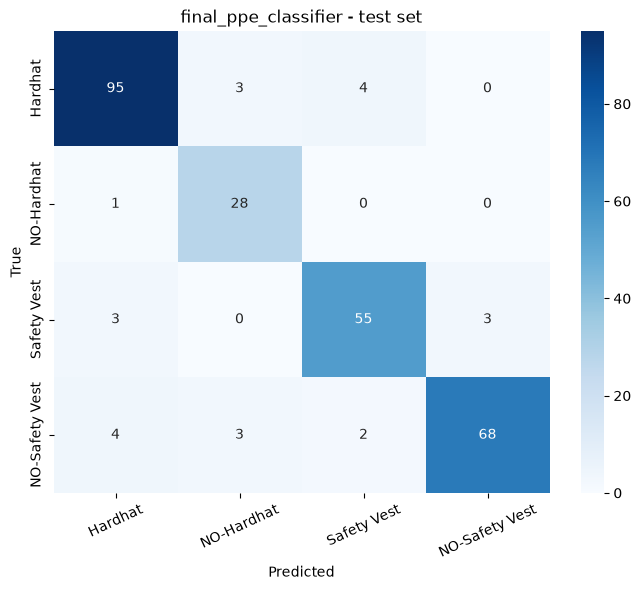

In [34]:
utils.plot_confusion_matrix(y_true, y_pred, f'{CHECKPOINT_NAME} - test set', save_name=None)